# 1. Data Analysis
- 생성 완료된 Kalasatama 360건의 전체 통계와 대표 예시 10건
- 전체 풍향 60개 × 풍속 6개, 학습 288건 / 검증 36건 / 시험 36건
- 코드는 유지하고 읽기 전용 실행 환경에서 manifest.collection.json을 입력 목록으로 연결한 결과
- 원본 10건용 manifest.json은 유지하며, 360건 재실행에는 동일한 입력 연결이 필요

In [2]:
# 분석 도구
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyvista as pv
from IPython.display import display

%matplotlib inline

In [3]:
# 분석 경로
DATA = Path('../data')
PREPROCESSED = DATA / 'preprocessed'
pv.set_plot_theme('document')
print(PREPROCESSED)

../data/preprocessed


## 1) 생성 조건
- 풍향 60개(0–354°, 6° 간격) × 풍속 6개(2, 3, 4, 5, 8, 10 m/s)
- 풍향은 +X축 기준 반시계 방향

In [4]:
manifest = json.loads((PREPROCESSED / 'manifest.json').read_text())
entries = manifest['cases']
conditions = pd.DataFrame([{
    '파일': e['file'], '풍향 [°]': e['wind_direction_deg'],
    '풍속 [m/s]': e['wind_speed_m_s'], '분할': e['split'],
    '상태': e['status'], '유효 유체 셀': e['valid_fluid_cells'],
} for e in entries])
display(conditions)
print('격자 ZYX:', manifest['grid_shape_zyx'])
print('분할:', conditions['분할'].value_counts().to_dict())

,파일,풍향 [°],풍속 [m/s],분할,상태,유효 유체 셀
0,wind_000_speed_03.npz,0,3,train,complete,1037115
1,wind_000_speed_08.npz,0,8,train,complete,1037115
2,wind_072_speed_03.npz,72,3,train,complete,1037115
3,wind_072_speed_08.npz,72,8,train,complete,1037115
4,wind_144_speed_03.npz,144,3,train,complete,1037115
5,wind_144_speed_08.npz,144,8,train,complete,1037115
6,wind_216_speed_03.npz,216,3,train,complete,1037115
7,wind_216_speed_08.npz,216,8,train,complete,1037115
8,wind_288_speed_03.npz,288,3,train,complete,1037115
9,wind_288_speed_08.npz,288,8,train,complete,1037115


격자 ZYX: [64, 128, 128]
분할: {'train': 288, 'val': 36, 'test': 36}


## 2) 생성 품질
- 저장된 격자 검사와 수렴 잔차

In [5]:
# 격자와 수렴 결과
print('CFD 셀:', manifest['generation']['cells'])
qc = pd.DataFrame([{
    '조건': f"{e['wind_direction_deg']}° / {e['wind_speed_m_s']} m/s",
    '수렴': e['qc']['converged'], '반복': int(e['qc']['iterations']),
    '속도 잔차': e['qc']['initial_residuals']['U'],
    '압력 잔차': e['qc']['initial_residuals']['p'],
    '유량 불균형': e['qc']['flux_imbalance'],
} for e in entries]).set_index('조건')
display(qc.style.format({'속도 잔차': '{:.2e}', '압력 잔차': '{:.2e}',
                         '유량 불균형': '{:.2e}'}))

CFD 셀: 470591


,수렴,반복,속도 잔차,압력 잔차,유량 불균형
조건,,,,,
0° / 3 m/s,True,541,9.96e-06,3.25e-05,0.00e+00
0° / 8 m/s,True,541,9.97e-06,3.53e-05,1.38e-11
72° / 3 m/s,True,442,9.85e-06,5.09e-05,1.30e-10
72° / 8 m/s,True,442,9.96e-06,5.15e-05,1.41e-10
144° / 3 m/s,True,527,3.84e-06,5.75e-05,0.00e+00
144° / 8 m/s,True,525,3.98e-06,3.90e-05,2.94e-11
216° / 3 m/s,True,501,9.83e-06,4.92e-05,7.85e-11
216° / 8 m/s,True,501,9.86e-06,4.99e-05,9.81e-11
288° / 3 m/s,True,429,6.87e-06,1.40e-05,1.53e-10


## 3) 대표 유동장
- 속도 [m/s], 압력 [Pa], 높이는 지면 기준

In [6]:
# 저장된 NPZ 읽기
def read_case(filename):
    """저장된 유동장과 좌표를 읽음"""
    with np.load(PREPROCESSED / filename, allow_pickle=False) as npz:
        case = {key: npz[key] for key in (
            'target', 'fluid_mask', 'valid_mask', 'origin', 'spacing', 'metadata')}
    case['metadata'] = json.loads(str(case['metadata']))
    return case

entry = entries[0]
case = read_case(entry['file'])
print(entry['file'], case['target'].shape)

wind_000_speed_03.npz (4, 64, 128, 128)


In [7]:
# 좌표와 물리량
origin, spacing = case['origin'], case['spacing']
fluid = case['fluid_mask'][0]
valid, solid = fluid & case['valid_mask'][0], ~fluid
shape = nz, ny, nx = fluid.shape
x, y, z = [origin[i] + (np.arange(shape[2 - i]) + 0.5) * spacing[i] for i in range(3)]
ground_z = case['metadata']['ground_z']
z_index = int(np.argmin(np.abs(z - ground_z - 10)))
speed, pressure = np.linalg.norm(case['target'][:3], axis=0), case['target'][3]
extent = [origin[0], origin[0] + nx * spacing[0], origin[1], origin[1] + ny * spacing[1]]
print(f'단면 높이: {z[z_index] - ground_z:.2f} m')

단면 높이: 10.14 m


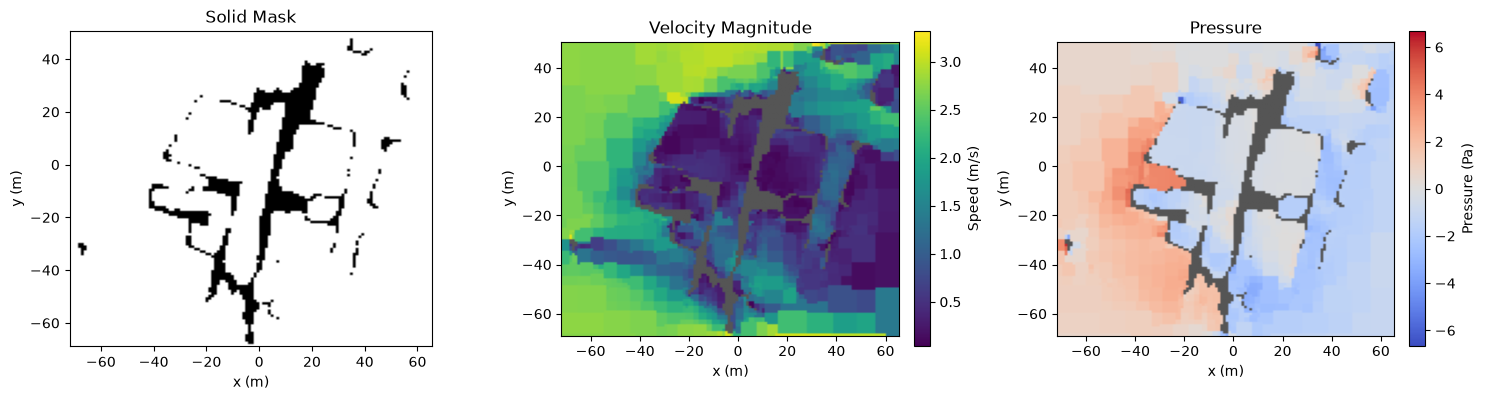

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(solid[z_index], origin='lower', extent=extent, cmap='gray_r', vmin=0, vmax=1)
axes[0].set_title('Solid Mask')
for ax, field, title, cmap, unit in [
    (axes[1], speed, 'Velocity Magnitude', 'viridis', 'm/s'),
    (axes[2], pressure, 'Pressure', 'coolwarm', 'Pa'),
]:
    values = np.ma.masked_where(~valid[z_index], field[z_index])
    colors = plt.get_cmap(cmap).copy()
    colors.set_bad('#555555')
    limits = {} if unit == 'm/s' else dict(vmin=-np.abs(values).max(), vmax=np.abs(values).max())
    image = ax.imshow(values, origin='lower', extent=extent, cmap=colors, **limits)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label=('Speed (m/s)' if unit == 'm/s' else 'Pressure (Pa)'))
for ax in axes:
    ax.set(xlabel='x (m)', ylabel='y (m)')
plt.tight_layout()
plt.show()

## 4) 장애물과 3D 유동
- 유체 마스크 × 유속, 전체 체적 표시

In [9]:
# 유체 마스크와 표시 격자
obs = fluid.astype('float32')
grid = pv.ImageData(dimensions=(nx, ny, nz), origin=origin + spacing / 2, spacing=spacing)
grid['obs'] = obs.ravel()
buildings = grid.contour([0.5], scalars='obs')
grid['speed'] = np.where(valid, obs * speed, 0).ravel()

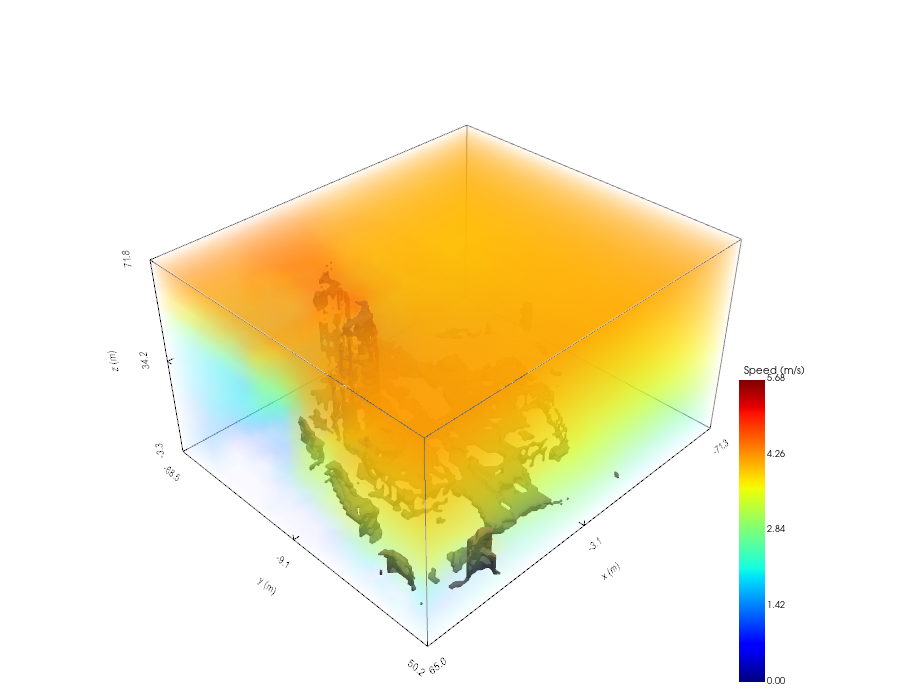

In [10]:
# 장애물과 유속 체적
plotter = pv.Plotter(off_screen=True, window_size=(900, 700))
clim = (0, speed[valid].max())
plotter.add_volume(grid, scalars='speed', cmap='jet', clim=clim, mapper='fixed_point',
                   opacity=[0, .02, .04, .08, .12, .18], opacity_unit_distance=3,
                   scalar_bar_args={'title': 'Speed (m/s)', 'vertical': True, 'use_opacity': False,
                                    'position_x': .82, 'title_font_size': 10, 'label_font_size': 9})
plotter.add_mesh(buildings, color='gray')
plotter.add_mesh(grid.outline(), color='gray', line_width=1)
plotter.show_bounds(xtitle='x (m)', ytitle='y (m)', ztitle='z (m)', font_size=8,
                    use_3d_text=False, n_xlabels=3, n_ylabels=3, n_zlabels=3, location='outer')
plotter.view_isometric()
plotter.camera.zoom(.9)
plotter.show(jupyter_backend='static')

## 5) 전체 통계와 대표 예시
- 통계 표는 전체 360건을 반영
- 비교 그림은 풍향 5개(0, 72, 144, 216, 288°)와 풍속 2개(3, 8 m/s)의 대표 10건만 표시
- 동일 높이와 전체 360건의 공통 색상 범위


In [11]:
slices, statistics = [], []
for e in entries:
    current = read_case(e['file'])
    mask = (current['valid_mask'] & current['fluid_mask'])[0]
    velocity = np.linalg.norm(current['target'][:3], axis=0)
    slices.append(np.ma.masked_where(~mask[z_index], velocity[z_index]))
    statistics.append({'조건': f"{e['wind_direction_deg']}° / {e['wind_speed_m_s']} m/s",
                       '평균 속도 [m/s]': velocity[mask].mean(), '최대 속도 [m/s]': velocity[mask].max(),
                       '최소 압력 [Pa]': current['target'][3][mask].min(),
                       '최대 압력 [Pa]': current['target'][3][mask].max()})
display(pd.DataFrame(statistics).set_index('조건').round(3))

,평균 속도 [m/s],최대 속도 [m/s],최소 압력 [Pa],최대 압력 [Pa]
조건,,,,
0° / 3 m/s,3.215,5.681000,-19.540001,12.402000
0° / 8 m/s,8.576,15.159000,-139.199997,88.221001
72° / 3 m/s,3.379,5.270000,-18.287001,12.013000
72° / 8 m/s,9.012,14.055000,-130.136002,85.462997
144° / 3 m/s,3.122,5.795000,-29.084000,11.316000
144° / 8 m/s,8.326,15.481000,-207.110001,80.484001
216° / 3 m/s,3.278,5.625000,-19.927000,11.513000
216° / 8 m/s,8.743,15.007000,-141.781998,81.889000
288° / 3 m/s,3.324,5.490000,-15.145000,13.008000


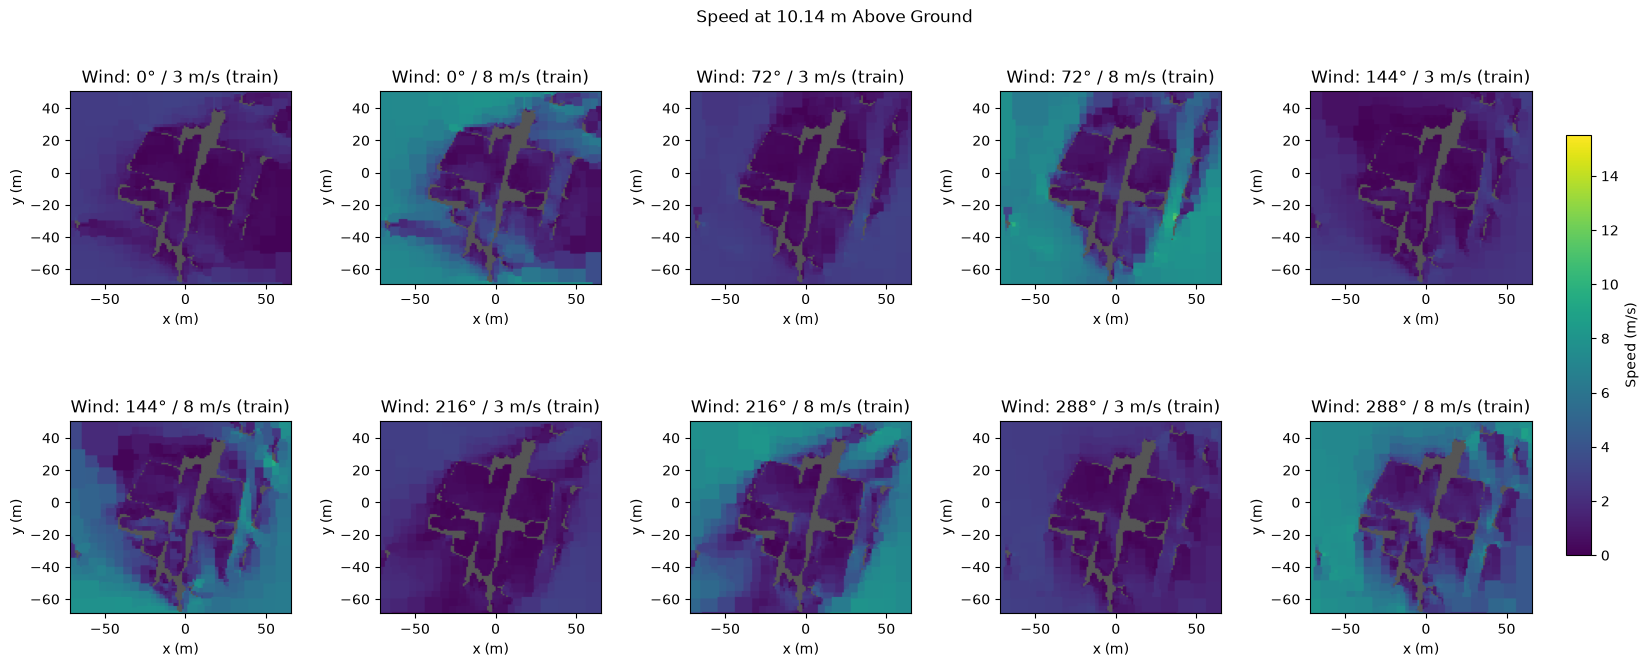

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(17, 7))
colors = plt.get_cmap('viridis').copy()
colors.set_bad('#555555')
vmax = max(float(field.max()) for field in slices)
for ax, e, field in zip(axes.flat, entries, slices):
    image = ax.imshow(field, origin='lower', extent=extent, cmap=colors, vmin=0, vmax=vmax)
    ax.set(title=f"Wind: {e['wind_direction_deg']}° / {e['wind_speed_m_s']} m/s ({e['split']})",
           xlabel='x (m)', ylabel='y (m)')
fig.suptitle(f'Speed at {z[z_index] - ground_z:.2f} m Above Ground')
fig.subplots_adjust(left=0.05, right=0.91, top=0.9, bottom=0.08, wspace=0.4, hspace=0.35)
fig.colorbar(image, cax=fig.add_axes([0.93, 0.2, 0.015, 0.6]), label='Speed (m/s)')
plt.show()